# GrENE-Net: frequency change of insertions and deletions vs matched SNPs

Two figures isolated from `sv_main_fig2-Copy1.ipynb` — same data, same code.

**Data.** kMate's per-pool allele frequencies (`garden_af_event.npz`, `_sv_garden_af.py`): the founding
frequency is the mean of the 8 seed-mix runs; a garden's frequency is the mean over its plots of each
plot's frequency at its last sampled generation (352 pools, 31 gardens). SV **event** = arch3 alleles of
a pangenome bubble merged with `truvari collapse` defaults; event frequency = sum of its alleles'
frequencies (capped at 1). Variants called in ≥ 90% of the 231 founders with ≥ 2 carrier founders; SNPs
a random 10% of records. Context, first match wins: CDS > UTR > intron > reference TE > promoter
(≤ 2 kb upstream) > intergenic.

**Statistic, per garden.** Relative change of the class's summed allele frequency from the seed mix
to the garden, **minus** the same for its matched SNPs (% of start). **Matching:** every event against
all SNPs of the **same context** carried by the **same number of founders** and by founders of the
**same origin-climate quintile**, weighted so the SNP set has the events' composition.

In [1]:

import os, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'figure.dpi':120,'font.size':8,'axes.linewidth':0.6,'savefig.bbox':'tight'})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]; SUMC=["CDS","intron","intergenic"]
KC={"snp":"0.15","indel":"0.62","ins":"#D95F02","del":"#1B9E77"}; KL={"snp":"SNPs","indel":"short indels","ins":"insertions","del":"deletions"}
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.9",lw=0.6,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
pfmt=lambda p: "p < 0.001" if p<=0.001 else f"p = {p:.2g}"
rng=np.random.default_rng(0)

GS=np.load(f"{G}/garden_af_event.npz"); PV=GS["p"].astype(np.float64); KD=GS["kind"].astype(str); CX=GS["ctx"]; ZN=GS["zone"].astype(str); BIO=GS["bio1"]
NCAR=GS["n"].astype(int); BQ=np.quantile(GS["b1"][KD=="snp"],[0.2,0.4,0.6,0.8]); QCL=np.digitize(GS["b1"],BQ)          # carrier-climate quintile (edges from SNPs)
CB=np.array([2,3,4,5,6,8,11,16,26,51,1000])
CELLX=NCAR*10+QCL                                   # exact match: same number of carrier founders x same carrier-climate quintile
CELLB=np.digitize(NCAR,CB)*10+QCL                   # fallback: carrier-count bin x quintile, used only when the exact cell holds no SNP
def matched_snps(ms,mn,cx=None,cb=None):
    # every event is compared with ALL SNPs of the comparison set in its cell (default: carrier count x climate quintile, CELLX;
    # fallback CELLB when the exact cell holds no SNP); the SNP set is weighted so its composition equals the events'
    cx=CELLX if cx is None else cx; cb=CELLB if cb is None else cb
    si=np.where(mn)[0]; w=np.zeros(si.size); ex=cx[si]; cbs=cb[si]
    cnt_ex=pd.Series(ex).value_counts(); cnt_cb=pd.Series(cbs).value_counts(); nfall=0
    for c,k in pd.Series(cx[ms]).value_counts().items():
        if c in cnt_ex.index: w[ex==c]+=k/cnt_ex[c]
        else:
            b=cb[ms][cx[ms]==c][0]; nfall+=k
            if b in cnt_cb.index: w[cbs==b]+=k/cnt_cb[b]
    return si,w,nfall
def load_diff(ms,mn,cx=None,cb=None):
    # per garden: relative change of the class's summed frequency (its load) minus the same for the matched SNPs
    si,w,_=matched_snps(ms,mn,cx,cb); Ls=np.nansum(PV[ms],0); Ln=np.nansum(PV[si]*w[:,None],0)
    return (Ls[1:]/Ls[0]-1)-(Ln[1:]/Ln[0]-1)
def _matched_null_compute(ms,mn,ndraw,seed):
    # random SNP sets with the class's composition: one SNP per event drawn from the event's exact cell (fallback: its bin cell), same statistic
    r=np.random.default_rng(seed); si,w,_=matched_snps(ms,mn); Ln=np.nansum(PV[si]*w[:,None],0); base=Ln[1:]/Ln[0]-1
    ex=CELLX[si]; cb=CELLB[si]; pools=[]
    for c,k in pd.Series(CELLX[ms]).value_counts().items():
        pool=si[ex==c]
        if pool.size==0: pool=si[cb==CELLB[ms][CELLX[ms]==c][0]]
        if pool.size: pools.append((pool,int(k)))
    out=np.empty(ndraw)
    for t in range(ndraw):
        pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); Ls=np.nansum(PV[pick],0); out[t]=(Ls[1:]/Ls[0]-1-base).mean()
    return out
def null_p(obs,null,two_sided=False):
    return (np.abs(null-null.mean())>=abs(obs-null.mean())).mean() if two_sided else (null<=obs).mean()
def matched_null(ms,mn,ndraw=1000,seed=1):
    # cached on disk (same cache as sv_main_fig2): keyed on the two masks and the data file's timestamp
    key=hashlib.md5(np.packbits(np.asarray(ms)).tobytes()+np.packbits(np.asarray(mn)).tobytes()+f"exact_{ndraw}_{seed}_{PV.shape}_{os.path.getmtime(f'{G}/garden_af_event.npz')}".encode()).hexdigest()[:16]
    os.makedirs(f"{G}/cache",exist_ok=True); f=f"{G}/cache/null_{key}.npy"
    if os.path.exists(f): return np.load(f)
    out=_matched_null_compute(ms,mn,ndraw,seed); np.save(f,out); return out
def bci(v,B=2000,seed=2):
    # percentile bootstrap CI of the mean over gardens (resample gardens with replacement)
    r=np.random.default_rng(seed); bs=r.choice(v,(B,v.size)).mean(1); return np.percentile(bs,2.5),np.percentile(bs,97.5)
print("events: "+", ".join(f"{KL[k]} {int((KD==k).sum()):,}" for k in ("ins","del"))+f";  SNPs {int((KD=='snp').sum()):,};  gardens {BIO.size} ({', '.join(f'{z} {int((ZN==z).sum())}' for z in ('cold','mid','hot'))})")


events: insertions 12,981, deletions 5,437;  SNPs 264,595;  gardens 31 (cold 11, mid 10, hot 10)


## Figure 1 — all gardens

All insertions (left) and all deletions (right) in coding sequence, introns and intergenic sequence.
One dot per garden (31), coloured by garden temperature; black = mean over gardens ± 95% percentile
bootstrap CI (2,000 resamples of gardens). **Brackets:** coding sequence against each non-coding
context within the SV type — per garden both are "class minus its own matched SNPs", so the contrast is
a difference of differences paired by garden; *p* = paired Wilcoxon signed-rank test over the 31
gardens (bold = p < 0.05). The printed tables add, for every class and every contrast, the two-sided
empirical p from 1,000 random matched SNP sets (`matched_snp_null_p`) — gardens share one founder
pool, so that is the stricter test.

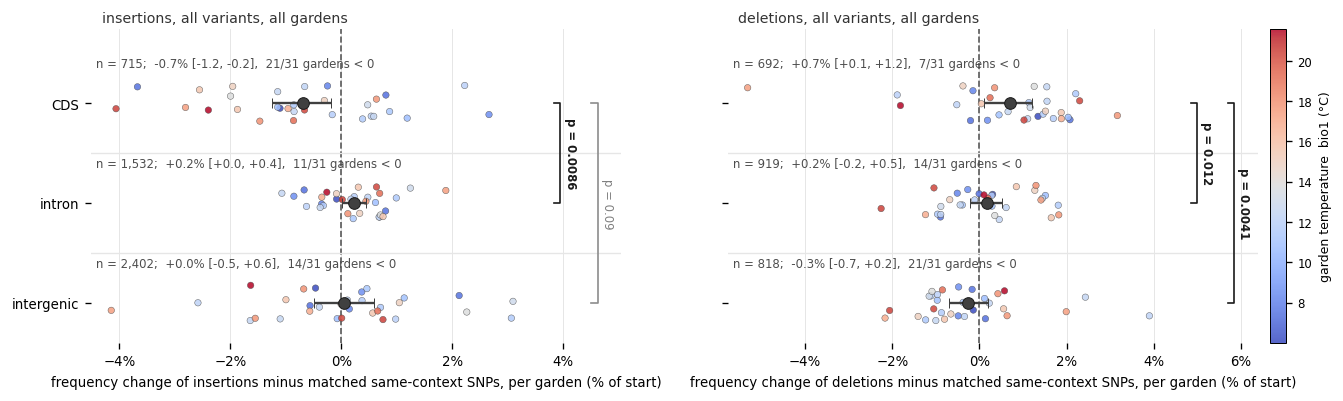

      kind    context  n_events  n_snps    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715   58560 -0.0069  -0.0125  -0.0018           True             21               0.385
insertions     intron      1532   55465  0.0022   0.0001   0.0045           True             11               0.496
insertions intergenic      2402   30992  0.0005  -0.0049   0.0058          False             14               0.894
 deletions        CDS       692   58560  0.0071   0.0011   0.0120           True              7               0.107
 deletions     intron       919   55465  0.0016  -0.0022   0.0053          False             14               0.667
 deletions intergenic       818   30992 -0.0027  -0.0070   0.0020          False             21               0.471

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  

In [2]:

def contrast(dA,nlA,dB,nlB,seed=3):
    # is context A (coding) different from context B? A - B is a difference of differences, paired by garden.
    # CI: percentile bootstrap over gardens of the mean paired difference. matched-SNP null: random matched SNP sets drawn
    # independently in each context, null difference = null_A - null_B (draws paired at random), two-sided around the null mean.
    df=dA-dB; lo,hi=bci(df); nd=nlA-np.random.default_rng(seed).permutation(nlB)
    return df.mean(),lo,hi,int((df<0).sum()),null_p(df.mean(),nd,two_sided=True),stats.wilcoxon(dA,dB).pvalue
fig,axes=plt.subplots(1,2,figsize=(13,3.4),sharey=True); rows=[]; crow=[]
for a,k in zip(axes,("ins","del")):
    style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--"); DN={}
    for yi,ctx in enumerate(SUMC):
        ci=CTX.index(ctx); ms=(KD==k)&(CX==ci); mn=(KD=="snp")&(CX==ci); d=load_diff(ms,mn); nl=matched_null(ms,mn); pe=null_p(d.mean(),nl,two_sided=True); lo,hi=bci(d); DN[ctx]=(d,nl)
        sc_=a.scatter(d,yi+rng.uniform(-0.18,0.18,d.size),c=BIO,cmap="coolwarm",vmin=BIO.min(),vmax=BIO.max(),s=15,alpha=0.85,linewidth=0.3,edgecolor="0.3",zorder=2)
        a.errorbar(d.mean(),yi,xerr=[[d.mean()-lo],[hi-d.mean()]],fmt="o",ms=7,color="0.25",mec="0.1",mew=0.6,capsize=3,elinewidth=1.4,zorder=3)
        a.annotate(f"n = {int(ms.sum()):,};  {100*d.mean():+.1f}% [{100*lo:+.1f}, {100*hi:+.1f}],  {(d<0).sum()}/31 gardens < 0",xy=(0.01,yi-0.46),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=7,color="0.3")
        rows.append(dict(kind=KL[k],context=ctx,n_events=int(ms.sum()),n_snps=int(mn.sum()),mean=d.mean(),boot_lo=lo,boot_hi=hi,ci_excludes_0=bool(hi<0 or lo>0),gardens_below=int((d<0).sum()),matched_snp_null_p=pe))
        if yi<2: a.axhline(yi+0.5,color="0.9",lw=0.8)
    x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.20*(x1-x0)); tr=a.get_yaxis_transform()      # room on the right for the brackets (x in axes fraction, y in data)
    for yi,(ctx,xb) in enumerate(zip(SUMC[1:],(0.885,0.955)),1):                        # coding sequence against each non-coding context
        m_,l_,h_,nb_,p_,pw_=contrast(*DN["CDS"],*DN[ctx]); sig=pw_<0.05
        a.plot([xb-0.012,xb,xb,xb-0.012],[0,0,yi,yi],transform=tr,color="0.1" if sig else "0.55",lw=1.0,clip_on=False,zorder=5)
        a.text(xb+0.006,yi/2,"p < 0.001" if pw_<0.001 else f"p = {pw_:.2g}",transform=tr,rotation=270,ha="left",va="center",fontsize=7,
               color="0.1" if sig else "0.5",fontweight="bold" if sig else "normal")
        crow.append(dict(kind=KL[k],contrast=f"CDS - {ctx}",mean_diff=m_,boot_lo=l_,boot_hi=h_,gardens_below=nb_,wilcoxon_p=pw_,significant=bool(sig),matched_snp_null_p=p_))
    a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.4,-0.75)
    a.set_xlabel(f"frequency change of {KL[k]} minus matched same-context SNPs, per garden (% of start)",fontsize=8); a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
    a.annotate(f"{KL[k]}, all variants, all gardens",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color="0.2")
cb=fig.colorbar(sc_,ax=axes,pad=0.01,fraction=0.025); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.savefig(f"{G}/plots/fig2_lead_frequency_all_gardens.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{G}/plots/fig2_lead_frequency_all_gardens.pdf",bbox_inches="tight"); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\ncoding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):")
print(pd.DataFrame(crow).round(4).to_string(index=False))


## Figure 2 — the same data, split by garden climate

Identical statistic and matching; the 31 gardens are grouped into climate zones (terciles of garden
annual mean temperature, bio1: cold, mid, hot). Small dots = individual gardens; large points = mean
over the gardens of a zone ± 95% percentile bootstrap CI (2,000 resamples of the zone's gardens). The
line of text in each row is the all-garden result of Figure 1 with its matched-SNP null p.

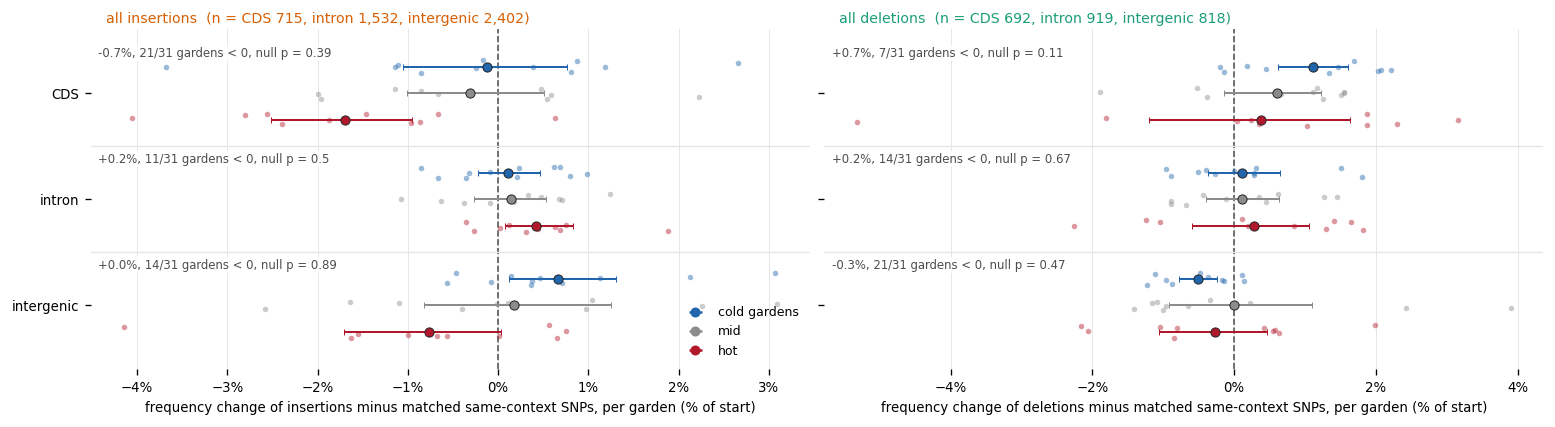

by garden climate zone:
      kind    context zone  n_gardens    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below
insertions        CDS cold         11 -0.0012  -0.0106   0.0076          False              6
insertions        CDS  mid         10 -0.0031  -0.0101   0.0051          False              6
insertions        CDS  hot         10 -0.0170  -0.0252  -0.0095           True              9
insertions     intron cold         11  0.0011  -0.0022   0.0046          False              5
insertions     intron  mid         10  0.0014  -0.0026   0.0053          False              4
insertions     intron  hot         10  0.0042   0.0008   0.0082           True              2
insertions intergenic cold         11  0.0066   0.0012   0.0131           True              3
insertions intergenic  mid         10  0.0018  -0.0082   0.0125          False              5
insertions intergenic  hot         10 -0.0076  -0.0171   0.0003          False              6
 deletions        CDS cold         1

In [3]:

ZC={"cold":"#2166AC","mid":"0.55","hot":"#B2182B"}; ZOFF={"cold":-0.25,"mid":0.0,"hot":0.25}
fig,ax=plt.subplots(1,2,figsize=(13,3.6),sharey=True); rows=[]
for a,k in zip(ax,("ins","del")):
    style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--")
    for yi,ctx in enumerate(SUMC):
        ci=CTX.index(ctx); ms=(KD==k)&(CX==ci); mn=(KD=="snp")&(CX==ci); d=load_diff(ms,mn); pe=null_p(d.mean(),matched_null(ms,mn),two_sided=True)
        for z in ("cold","mid","hot"):
            dz=d[ZN==z]; a.scatter(dz,yi+ZOFF[z]+rng.uniform(-0.06,0.06,dz.size),s=11,color=ZC[z],alpha=0.45,linewidth=0,zorder=2)
            lo,hi=bci(dz); a.errorbar(dz.mean(),yi+ZOFF[z],xerr=[[dz.mean()-lo],[hi-dz.mean()]],fmt="o",ms=5.5,color=ZC[z],mec="0.15",mew=0.6,capsize=2,elinewidth=1.2,zorder=3)
            rows.append(dict(kind=KL[k],context=ctx,zone=z,n_gardens=int(dz.size),mean=dz.mean(),boot_lo=lo,boot_hi=hi,ci_excludes_0=bool(hi<0 or lo>0),gardens_below=int((dz<0).sum())))
        a.annotate(f"{100*d.mean():+.1f}%, {(d<0).sum()}/31 gardens < 0, null {pfmt(pe)}",xy=(0.01,yi-0.44),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=7,color="0.3",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none",pad=1))
        if yi<2: a.axhline(yi+0.5,color="0.9",lw=0.8)
    a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.6,-0.6)
    a.set_xlabel(f"frequency change of {KL[k]} minus matched same-context SNPs, per garden (% of start)",fontsize=8); a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
    a.annotate(f"all {KL[k]}  (n = "+", ".join(f"{c} {int(((KD==k)&(CX==CTX.index(c))).sum()):,}" for c in SUMC)+")",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color=KC[k])
for z,l in (("cold","cold gardens"),("mid","mid"),("hot","hot")): ax[0].errorbar([],[],xerr=[],fmt="o",ms=5,color=ZC[z],label=l)
ax[0].legend(frameon=False,fontsize=7.5,loc="lower right")
fig.tight_layout(); fig.savefig(f"{G}/plots/fig2_lead_frequency_by_garden_climate.png",dpi=200); fig.savefig(f"{G}/plots/fig2_lead_frequency_by_garden_climate.pdf"); plt.show()
print("by garden climate zone:"); print(pd.DataFrame(rows).round(4).to_string(index=False))
